# Etapa 4: Aprendizaje por Refuerzo (Q-Learning para Mitigacion de Amenazas en Tiempo Real)
**Materia:** Machine Learning y Ciencia de los Datos (2026)  
**Docente:** Lic. Patricia Rodriguez Bilbao  
**Institucion:** Universidad Mayor de San Simon (UMSS)  
**Area de Aplicacion:** Ciberseguridad / Mitigacion Activa de Phishing en Firewalls  
**Fundamentacion Teorica:** Diapositivas Oficiales - *1.11 Aprendizaje por Refuerzo (MDP y Bellman Optimality)*

---

### Formulacion del Problema de Refuerzo (Proceso de Decision de Markov - MDP):
* **Agente Inteligente:** Sistema de Deteccion y Respuesta a Amenazas (Firewall Autonomo).
* **Entorno ($S$):** Flujo de URLs entrantes parametrizadas por longitud, tasa de caracteres especiales y protocolo criptografico HTTPS.
* **Espacio de Acciones ($A$):**
  * `a = 0`: **Permitir Trafico (Allow / Passthrough)** - Libre navegacion para el usuario.
  * `a = 1`: **Bloquear Trafico (Block / Drop)** - Intercepcion inmediata ante sospecha fundada.
  * `a = 2`: **Inspeccion Profunda en Sandbox (Isolate)** - Aislamiento en entorno virtual seguro para analisis forense.
* **Funcion de Recompensa $R(s, a)$:**
  * Permitir URL Legitima: `+10` (transito normal sin friccion al usuario).
  * Bloquear URL de Phishing: `+15` (amenaza neutralizada con exito).
  * Falso Positivo (Bloquear legitima): `-20` (interrupcion operativa innecesaria).
  * Falso Negativo (Permitir phishing): `-100` (penalizacion maxima por brecha de seguridad).
  * Envio a Sandbox: `+8` si era phishing (contencion segura) / `+2` si era benigna (costo minimo de latencia).
* **Regla de Actualizacion de Bellman (Q-Learning):**
  $$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$
* **Estrategia de Exploracion:** $\epsilon$-greedy con decaimiento temporal ($\epsilon \in [1.0 \to 0.05]$).

In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajuste de rutas
NOTEBOOK_DIR = os.getcwd()
BASE_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, "..", ".."))
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

from src.data_loader import load_phiusiil_processed

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

GUARDADOS_DIR = os.path.join(BASE_DIR, "models", "reinforcement_learning", "guardados")
RESULTADOS_DIR = os.path.join(BASE_DIR, "models", "reinforcement_learning", "resultados")
DOCS_FIGS_DIR = os.path.join(BASE_DIR, "docs", "pre_informe_1", "figuras")

os.makedirs(GUARDADOS_DIR, exist_ok=True)
os.makedirs(RESULTADOS_DIR, exist_ok=True)
os.makedirs(DOCS_FIGS_DIR, exist_ok=True)

print(f"[OK] Entorno de Aprendizaje por Refuerzo listo en: {BASE_DIR}")

[OK] Entorno de Aprendizaje por Refuerzo listo en: C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026


## 1. Carga de Datos y Definicion del Entorno de Simulacion (Defensive Environment)
Se crea la clase `EntornoDefensaURL` que simula la llegada de paquetes de red y URLs evaluadas por el Firewall.

In [2]:
train_df, test_df = load_phiusiil_processed()

class EntornoDefensaURL:
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
        self.n_muestras = len(self.df)
        self.indice_actual = 0

    def reset(self):
        self.indice_actual = np.random.randint(0, self.n_muestras)
        return self._obtener_estado()

    def _obtener_estado(self):
        fila = self.df.iloc[self.indice_actual]
        # Discretizacion en espacio de estados: (s_len: 4, s_sym: 3, https: 2) -> 24 estados
        longitud = fila.get("URLLength", 0)
        if longitud < -0.5:
            s_len = 0
        elif longitud < 0.2:
            s_len = 1
        elif longitud < 1.0:
            s_len = 2
        else:
            s_len = 3

        simbolos = fila.get("CharContinuationRate", 0)
        if simbolos < -0.2:
            s_sym = 0
        elif simbolos < 0.5:
            s_sym = 1
        else:
            s_sym = 2

        https = int(fila.get("IsHTTPS", 0) > 0)
        return (s_len, s_sym, https)

    def paso(self, accion):
        etiqueta_real = int(self.df.iloc[self.indice_actual]["label"])  # 0: Legitimo, 1: Phishing
        
        if accion == 0:  # PERMITIR (Allow)
            recompensa = 10.0 if etiqueta_real == 0 else -100.0  # Penalizacion severa por brecha
        elif accion == 1:  # BLOQUEAR (Block)
            recompensa = 15.0 if etiqueta_real == 1 else -20.0   # Falso positivo
        elif accion == 2:  # SANDBOX (Aislar)
            recompensa = 8.0 if etiqueta_real == 1 else 2.0      # Verificacion segura
        else:
            recompensa = 0.0

        self.indice_actual = np.random.randint(0, self.n_muestras)
        siguiente_estado = self._obtener_estado()
        return siguiente_estado, recompensa, etiqueta_real

entorno = EntornoDefensaURL(train_df)
print(f"[OK] Entorno inicializado sobre {len(train_df):,} muestras de red.")

[INFO] Cargando train.csv y test.csv desde C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\data\phiusiil\processed...


[OK] Datos listos: Train (188,296 filas), Test (47,074 filas).
[OK] Entorno inicializado sobre 188,296 muestras de red.


## 2. Entrenamiento del Agente con Q-Learning (Ecuacion de Bellman)
Implementamos el algoritmo de Q-Learning tabular evaluando 10,000 episodios con política $\epsilon$-greedy y decaimiento exponencial.

In [3]:
# Inicializacion de la Tabla Q: (4 x 3 x 2 x 3 acciones)
Q = np.zeros((4, 3, 2, 3))

alpha = 0.1          # Tasa de aprendizaje
gamma = 0.9          # Factor de descuento
epsilon = 1.0        # Exploracion inicial
epsilon_min = 0.05
epsilon_decay = 0.9995
episodios = 10000
pasos_por_episodio = 30

historial_recompensas = []
aciertos_hist = []

print(f"[INFO] Entrenando agente Q-Learning por {episodios:,} episodios...")

for ep in range(episodios):
    estado = entorno.reset()
    recompensa_ep = 0
    aciertos_ep = 0

    for _ in range(pasos_por_episodio):
        # Seleccion de accion: Exploracion vs Explotacion
        if np.random.rand() < epsilon:
            accion = np.random.randint(0, 3)
        else:
            accion = int(np.argmax(Q[estado]))

        siguiente_estado, recompensa, etiqueta_real = entorno.paso(accion)

        # Regla de actualizacion de Bellman
        mejor_siguiente = np.max(Q[siguiente_estado])
        Q[estado][accion] += alpha * (recompensa + gamma * mejor_siguiente - Q[estado][accion])

        # Registro de eficacia
        if (accion == 0 and etiqueta_real == 0) or (accion in [1, 2] and etiqueta_real == 1):
            aciertos_ep += 1

        estado = siguiente_estado
        recompensa_ep += recompensa

    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

    historial_recompensas.append(recompensa_ep)
    aciertos_hist.append(aciertos_ep / pasos_por_episodio)

    if (ep + 1) % 2500 == 0:
        print(f"      Episodio {ep+1:5d} / {episodios} | Recompensa Media: {np.mean(historial_recompensas[-500:]):6.1f} | Epsilon: {epsilon:.3f}")

print("[OK] Agente entrenado exitosamente.")

[INFO] Entrenando agente Q-Learning por 10,000 episodios...


      Episodio  2500 / 10000 | Recompensa Media:   57.1 | Epsilon: 0.286


      Episodio  5000 / 10000 | Recompensa Media:  233.9 | Epsilon: 0.082


      Episodio  7500 / 10000 | Recompensa Media:  266.2 | Epsilon: 0.050


      Episodio 10000 / 10000 | Recompensa Media:  274.7 | Epsilon: 0.050
[OK] Agente entrenado exitosamente.


## 3. Curva de Convergencia y Rendimiento del Agente
Visualizamos la recompensa acumulada y la efectividad porcentual en mitigación de ataques a lo largo del tiempo.

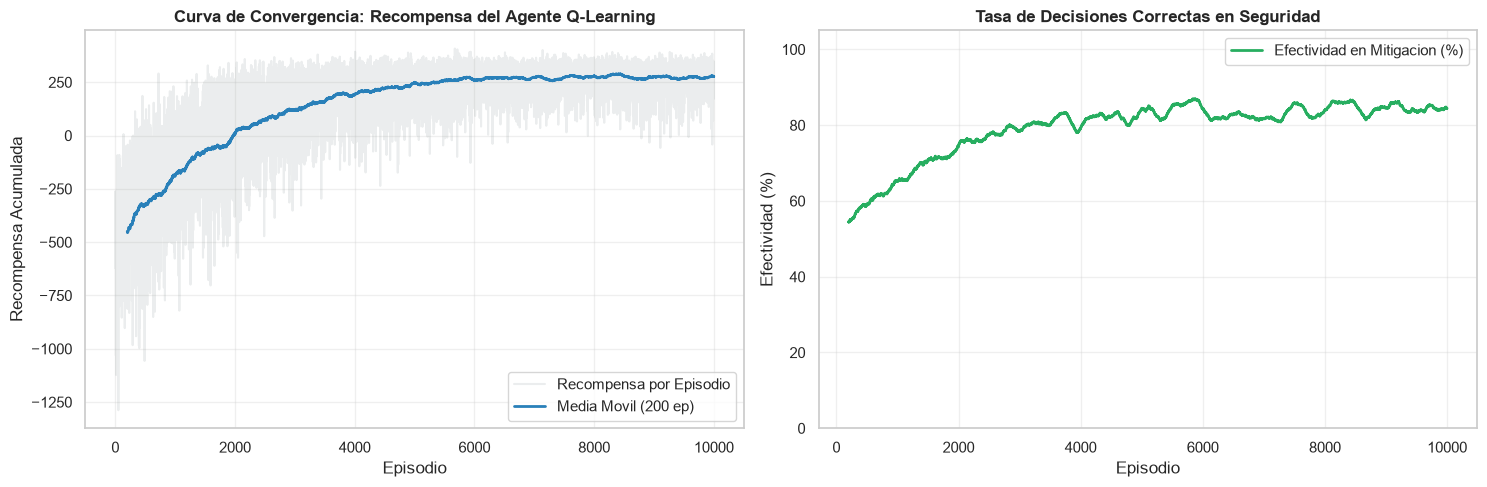

Recompensa Media Inicial (Episodios 1-500):    -382.8
Recompensa Media Final   (Episodios 9500-10000): 274.7
Efectividad Final en Seguridad:                 84.66%


In [4]:
ventana = 200
media_movil_rec = pd.Series(historial_recompensas).rolling(window=ventana).mean()
media_movil_acierto = pd.Series(aciertos_hist).rolling(window=ventana).mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Curva 1: Recompensa Acumulada
ax1.plot(historial_recompensas, alpha=0.15, color="#7f8c8d", label="Recompensa por Episodio")
ax1.plot(media_movil_rec, color="#2980b9", lw=2, label=f"Media Movil ({ventana} ep)")
ax1.set_title("Curva de Convergencia: Recompensa del Agente Q-Learning", fontweight="bold")
ax1.set_xlabel("Episodio")
ax1.set_ylabel("Recompensa Acumulada")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Curva 2: Tasa de Decisiones Seguras
ax2.plot(media_movil_acierto, color="#27ae60", lw=2, label="Efectividad en Mitigacion (%)")
ax2.set_title("Tasa de Decisiones Correctas en Seguridad", fontweight="bold")
ax2.set_xlabel("Episodio")
ax2.set_ylabel("Efectividad (%)")
ax2.set_ylim(0, 105)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Recompensa Media Inicial (Episodios 1-500):    {np.mean(historial_recompensas[:500]):.1f}")
print(f"Recompensa Media Final   (Episodios 9500-10000): {np.mean(historial_recompensas[-500:]):.1f}")
print(f"Efectividad Final en Seguridad:                 {np.mean(aciertos_hist[-500:])*100:.2f}%")

## 4. Analisis de la Politica Optima $\pi^*(s)$ y Serializacion
Analizamos la matriz de decisiones aprendida por el agente y guardamos la tabla Q en disco.

In [5]:
# Muestra de la politica aprendida para diferentes estados clave
nombres_acciones = {0: "PERMITIR (Allow)", 1: "BLOQUEAR (Block)", 2: "SANDBOX (Isolate)"}
nombres_longitud = {0: "Corta", 1: "Normal", 2: "Larga", 3: "Muy Larga"}
nombres_https = {0: "HTTP (Inseguro)", 1: "HTTPS (Seguro)"}

filas_politica = []
for s_len in range(4):
    for https in range(2):
        estado_ej = (s_len, 1, https)
        accion_optima = int(np.argmax(Q[estado_ej]))
        filas_politica.append({
            "Longitud URL": nombres_longitud[s_len],
            "Protocolo": nombres_https[https],
            "Accion Optima Aprendida": nombres_acciones[accion_optima],
            "Valor Q(s, a)": float(np.max(Q[estado_ej]))
        })

df_politica = pd.DataFrame(filas_politica)
print("=== MATRIZ DE DECISIONES DE LA POLITICA OPTIMA (MUESTRA) ===")
display(df_politica)

# Serializar Tabla Q
q_table_path = os.path.join(GUARDADOS_DIR, "q_table_phishing.pkl")
joblib.dump(Q, q_table_path)
print(f"[OK] Tabla Q serializada exitosamente en: {q_table_path}")

=== MATRIZ DE DECISIONES DE LA POLITICA OPTIMA (MUESTRA) ===


,Longitud URL,Protocolo,Accion Optima Aprendida,"Valor Q(s, a)"
0,Corta,HTTP (Inseguro),PERMITIR (Allow),0.000000
1,Corta,HTTPS (Seguro),PERMITIR (Allow),0.000000
2,Normal,HTTP (Inseguro),PERMITIR (Allow),101.841494
3,Normal,HTTPS (Seguro),SANDBOX (Isolate),98.209007
4,Larga,HTTP (Inseguro),PERMITIR (Allow),103.468452
5,Larga,HTTPS (Seguro),SANDBOX (Isolate),94.943099
6,Muy Larga,HTTP (Inseguro),SANDBOX (Isolate),92.856616
7,Muy Larga,HTTPS (Seguro),PERMITIR (Allow),102.574344


[OK] Tabla Q serializada exitosamente en: C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\models\reinforcement_learning\guardados\q_table_phishing.pkl
